In [1]:
import pandas as pd
from functools import reduce
import numpy as np  

In [2]:
#Wczytanie danych
PKN=pd.read_csv("Dane/PKN_d.csv")
PKN["Data"] = pd.to_datetime(PKN["Data"])
PKN = PKN.sort_values("Data")
PKN = PKN[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_PKN"})

PKN = PKN.sort_values("Data").reset_index(drop=True)
PKN = PKN[(PKN["Data"] >= "2015-01-01") & (PKN["Data"] <= "2019-12-31")]
PKN = PKN.reset_index(drop=True)

PKN

,Data,Close_PKN
0,2015-01-02,27.8994
1,2015-01-05,27.4398
2,2015-01-07,28.6976
3,2015-01-08,29.4787
4,2015-01-09,29.4614
...,...,...
1242,2019-12-19,57.3020
1243,2019-12-20,56.4693
1244,2019-12-23,57.1679
1245,2019-12-27,57.7050


In [3]:
PKN['Log_Return'] = np.log(PKN['Close_PKN'] / PKN['Close_PKN'].shift(1))

PKN

,Data,Close_PKN,Log_Return
0,2015-01-02,27.8994,NaN
1,2015-01-05,27.4398,-0.016611
2,2015-01-07,28.6976,0.044819
3,2015-01-08,29.4787,0.026854
4,2015-01-09,29.4614,-0.000587
...,...,...,...
1242,2019-12-19,57.3020,0.012266
1243,2019-12-20,56.4693,-0.014638
1244,2019-12-23,57.1679,0.012295
1245,2019-12-27,57.7050,0.009351


In [4]:
PKN['Close_PKN'].describe()

count    1247.000000
mean       54.145686
std        13.422179
min        27.439800
25%        40.524100
50%        56.384700
75%        65.806050
max        83.617300
Name: Close_PKN, dtype: float64

In [5]:
PKN['Log_Return'].describe()

count    1246.000000
mean        0.000582
std         0.019571
min        -0.081174
25%        -0.011092
50%         0.000403
75%         0.012758
max         0.065350
Name: Log_Return, dtype: float64

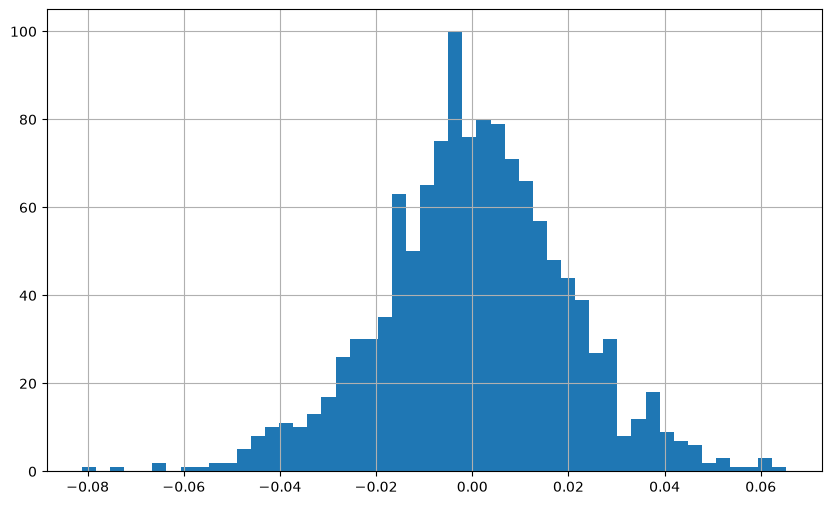

In [6]:
hist_PKN = PKN['Log_Return'].hist(bins=50, figsize=(10, 6))